In [78]:
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import pymc as pm
from pymc.pytensorf import collect_default_updates
import numpy as np
import pytensor
import pytensor.tensor as pt
from scipy.linalg import toeplitz
import prior_generation as pg

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Model 3

Separate mode transition matrices without pooling.

In [79]:
PITCH_ALPHABET = list("abcdefghjklmnopqrs")
V = len(PITCH_ALPHABET)
SEQ_LEN = 50
N_MODES = 4



In [80]:
def plot_heatmap(matrix):
    plt.imshow(matrix, cmap='binary')
    plt.colorbar()
    plt.show()


In [81]:
def step_fn(x_prev, A):
    p_next = A[x_prev]
    x_tp1 = pm.Categorical.dist(p_next)
    return x_tp1, collect_default_updates([x_tp1])

def scan_dist(x_0, A, length, size):
    sequence, _ = pytensor.scan(
        fn=step_fn,
        outputs_info=[x_0],
        non_sequences=[A],
        n_steps=length - 1,
        strict=True,
    )
    return sequence

coords = {
    "steps": range(SEQ_LEN - 1),
    "full_sequence": range(SEQ_LEN),
}

with pm.Model(coords=coords) as model:
    length = pm.Poisson("length", SEQ_LEN)
    
    nu = pm.Dirichlet("nu", a=np.ones(N_MODES))
    m = pm.Categorical("m", p=nu)
    
    beta = pt.stack([pg.transpose_beta(pg.get_beta(), m) for m in range(N_MODES)])
    A = pm.Dirichlet("A", a=beta)
    
    pi = pm.Dirichlet("pi", a=pg.get_alpha_m(m))
    x_0 = pm.Categorical("x_0", p=pi) 
    
    steps = pm.CustomDist(
        "x_t+1",
        x_0,
        A[m],
        length,
        dist=scan_dist,
    )

/var/folders/64/v2j39fj147b5_y9gs8478v2m0000gn/T/ipykernel_70466/3995899004.py:7: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  sequence, _ = pytensor.scan(
/var/folders/64/v2j39fj147b5_y9gs8478v2m0000gn/T/ipykernel_70466/3995899004.py:7: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  sequence, _ = pytensor.scan(


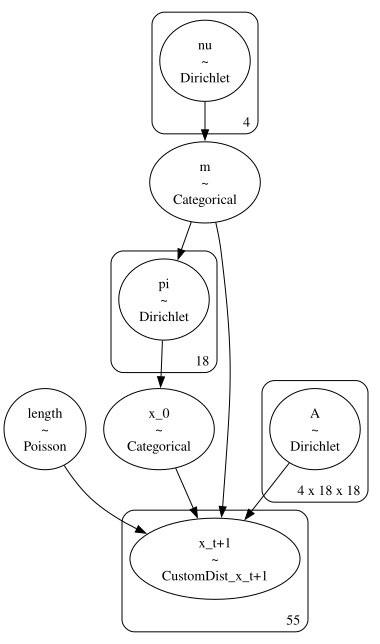

In [82]:
pm.model_to_graphviz(model)

In [88]:
with model:
    prior_samples = pm.sample_prior_predictive(samples=1)

import utils as u
import pandas as pd
pitch_0 = prior_samples.prior["x_0"].to_series()
pitch_series = prior_samples.prior["x_t+1"].to_series()

sequence = pd.concat([pitch_0, pitch_series])

melody = u.to_pitches(sequence, PITCH_ALPHABET)[::-1]
u.to_volpiano(melody)

Sampling: [A, length, m, nu, pi, x_0, x_t+1]


In [89]:
prior_samples.prior

<xarray.Dataset> Size: 12kB
Dimensions:      (chain: 1, draw: 1, x_t+1_dim_0: 48, A_dim_0: 4, A_dim_1: 18,
                  A_dim_2: 18, pi_dim_0: 18, nu_dim_0: 4)
Coordinates:
  * chain        (chain) int64 8B 0
  * draw         (draw) int64 8B 0
  * x_t+1_dim_0  (x_t+1_dim_0) int64 384B 0 1 2 3 4 5 6 ... 41 42 43 44 45 46 47
  * A_dim_0      (A_dim_0) int64 32B 0 1 2 3
  * A_dim_1      (A_dim_1) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
  * A_dim_2      (A_dim_2) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
  * pi_dim_0     (pi_dim_0) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
  * nu_dim_0     (nu_dim_0) int64 32B 0 1 2 3
Data variables:
    x_t+1        (chain, draw, x_t+1_dim_0) int64 384B 6 5 7 9 ... 14 12 12 14
    A            (chain, draw, A_dim_0, A_dim_1, A_dim_2) float64 10kB 0.0634...
    pi           (chain, draw, pi_dim_0) float64 144B 0.001143 ... 1.43e-135
    length       (chain, draw) int64 8B 49
    m            (chain, draw) int64 8B 3
    nu           (chain, draw, nu_dim_0) float64 32B 0.09278 0.0652 0.16 0.6821
    x_0          (chain, draw) int64 8B 6
Attributes:
    created_at:                 2026-03-16T12:51:07.374470+00:00
    arviz_version:              0.23.4
    inference_library:          pymc
    inference_library_version:  5.28.1

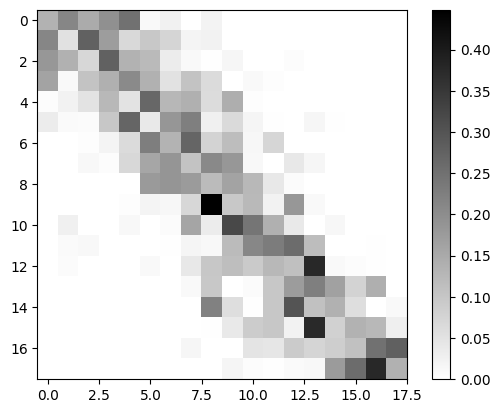

In [90]:
prev_mode = 1
plot_heatmap(prior_samples.prior.A.sel(chain=0, draw=0, A_dim_0=prev_mode))

In [86]:
print(prior_samples.prior.A.sel(chain=0, draw=0, A_dim_0=prev_mode))

<xarray.DataArray 'A' (A_dim_1: 18, A_dim_2: 18)> Size: 3kB
array([[1.30265254e-001, 1.32061055e-001, 3.19138284e-001,
        1.68014992e-001, 1.18451984e-001, 1.02455098e-001,
        2.85579955e-002, 6.58543093e-005, 3.95103217e-007,
        1.07115020e-025, 6.90220998e-004, 6.26868861e-013,
        2.98866957e-004, 1.34890243e-032, 2.27891682e-208,
        5.85496913e-118, 1.62231726e-022, 8.85707727e-035],
       [2.87974947e-001, 2.89917482e-002, 3.07866119e-001,
        1.50428254e-001, 7.76497128e-002, 7.48442136e-002,
        9.51695694e-003, 1.33270424e-002, 4.86395828e-002,
        3.31391167e-004, 4.30032361e-004, 1.69604423e-013,
        3.44479737e-023, 1.23243495e-010, 0.00000000e+000,
        8.88473467e-110, 8.12655973e-318, 5.19495033e-087],
       [1.12743928e-001, 9.28682633e-002, 9.33733126e-002,
        2.31238605e-001, 2.24858585e-001, 9.71685817e-002,
        8.86648568e-002, 5.45477757e-002, 3.17710183e-003,
        6.21427027e-007, 1.77879165e-006, 1.04752319e

In [87]:
print(prior_samples.prior.A.sel(chain=0, draw=0, A_dim_0=prev_mode))

<xarray.DataArray 'A' (A_dim_1: 18, A_dim_2: 18)> Size: 3kB
array([[1.30265254e-001, 1.32061055e-001, 3.19138284e-001,
        1.68014992e-001, 1.18451984e-001, 1.02455098e-001,
        2.85579955e-002, 6.58543093e-005, 3.95103217e-007,
        1.07115020e-025, 6.90220998e-004, 6.26868861e-013,
        2.98866957e-004, 1.34890243e-032, 2.27891682e-208,
        5.85496913e-118, 1.62231726e-022, 8.85707727e-035],
       [2.87974947e-001, 2.89917482e-002, 3.07866119e-001,
        1.50428254e-001, 7.76497128e-002, 7.48442136e-002,
        9.51695694e-003, 1.33270424e-002, 4.86395828e-002,
        3.31391167e-004, 4.30032361e-004, 1.69604423e-013,
        3.44479737e-023, 1.23243495e-010, 0.00000000e+000,
        8.88473467e-110, 8.12655973e-318, 5.19495033e-087],
       [1.12743928e-001, 9.28682633e-002, 9.33733126e-002,
        2.31238605e-001, 2.24858585e-001, 9.71685817e-002,
        8.86648568e-002, 5.45477757e-002, 3.17710183e-003,
        6.21427027e-007, 1.77879165e-006, 1.04752319e